# Demand & production forecasting: training and 2026 backtest

Trains the two models, evaluates them on 2026, then trains the final models on **all** data
and saves them for the app:

| model | class | file | predicts |
|---|---|---|---|
| ML 1 demand | `DemandForecaster` (`demand_model.py`) | `models/demand_model.pkl` | `actual_total_load` |
| ML 2 production | `ProductionForecaster` (`production_model.py`) | `models/production_model.pkl` | solar, wind, total production |

```python
from predictions import DemandForecaster, ProductionForecaster
DemandForecaster.load().predict([ts1, ts2, ...])      # any 15-min timestamps up to 7 days ahead
```
or over HTTP: `uvicorn predictions.api:app`, then `POST /forecast/demand`, `/forecast/production`, `/forecast`.

**How the model works**
- Four series (demand in ML 1; solar, wind, other in ML 2), each with LightGBM quantile models (10 / 50 / 90 %):

| series | what drives it | divided by (recent level) |
|---|---|---|
| `actual_total_load` (demand) | calendar, temperature | mean of the last 7 days |
| `solar` | irradiance, cloud, sun angle | max of the last 30 days (tracks capacity growth) |
| `wind_onshore` | wind speed | max of the last 365 days |
| `other_production` = total − solar − wind | dispatched to follow demand | mean of the last 7 days |

- Each sample is a pair (target time `T`, issue time `issued_at`); only data before `issued_at`
  is used, so one model serves every lead time from 15 min to 7 days (`lead_hours` is a feature).
- The model predicts a **correction to a base forecast**: `base = w·last_known + (1−w)·seasonal`
  with `w = exp(−(lead_hours − 0.25)/3)`, i.e. the last value for the next interval, sliding to
  last week / yesterday / the 24 h mean at long leads. Corrections are divided by
  `σ = sqrt(min(lead_hours, 24)/24)`, so short-lead corrections stay small.
- Overfitting control: early stopping on the 3 months before the training cut-off, then a refit.
  The same 3 months calibrate the ranges so they cover about 80 %.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "predictions" else Path.cwd()
sys.path.insert(0, str(ROOT))
from predictions import DemandForecaster, ProductionForecaster
from predictions.core import DAY, MAX_LEAD_STEPS, STEP, WEEK, load_data

REPORT_DIR = ROOT / "predictions" / "reports"
REPORT_DIR.mkdir(exist_ok=True)
TRAIN_END = int(pd.Timestamp("2026-01-01", tz="UTC").timestamp())

# chart colours, fixed order: model, persistence, weekly naive, actual
C_MODEL, C_PERSIST, C_WEEKLY, C_ACTUAL = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

## 1. Load and check the data

In [2]:
data = load_data()
steps = data.timestamp.diff().dropna().value_counts()
print(f"rows: {len(data):,}")
print(f"range: {pd.to_datetime(data.timestamp.min(), unit='s')} -> {pd.to_datetime(data.timestamp.max(), unit='s')} UTC")
print(f"time steps (s): {dict(steps)}" + ("   <- all 15 min, no gaps" if list(steps.index) == [900] else ""))
print(f"invalid rows (blanked in targets): {(data.valid == 0).sum()}")
print(f"train rows: {(data.timestamp < TRAIN_END).sum():,}   test rows (2026): {(data.timestamp >= TRAIN_END).sum():,}")

year = pd.to_datetime(data.timestamp, unit="s").dt.year
data.groupby(year)[["actual_total_load", "solar", "wind_onshore", "other_production"]].agg(["mean", "max"]).round(0)

rows: 140,302
range: 2022-11-07 00:00:00 -> 2026-11-07 11:15:00 UTC
time steps (s): {900.0: np.int64(140301)}   <- all 15 min, no gaps
invalid rows (blanked in targets): 48
train rows: 110,496   test rows (2026): 29,806


actual_total_load          solar         wind_onshore          \
                       mean     max   mean     max         mean     max   
timestamp                                                                 
2022                 6476.0  8276.0   57.0   567.0        776.0  2578.0   
2023                 6092.0  8656.0  167.0   905.0        851.0  2766.0   
2024                 6183.0  8785.0  238.0  1265.0        721.0  2742.0   
2025                 6114.0  8964.0  310.0  1845.0        671.0  2726.0   
2026                 5809.0  9296.0  586.0  3395.0        747.0  2936.0   

          other_production          
                      mean     max  
timestamp                           
2022                5695.0  7097.0  
2023                5416.0  7898.0  
2024                4850.0  7533.0  
2025                4438.0  6689.0  
2026                3883.0  6971.0

Solar's 2026 peak is almost double the training years and demand is about 5 % lower, which is
why every series is divided by its recent level: tree models can't output values outside the
range they were trained on.

## 2. Train both models on data before 2026

In [3]:
t0 = time.time()
demand = DemandForecaster.fit(data, train_end=TRAIN_END)
production = ProductionForecaster.fit(data, train_end=TRAIN_END)
print(f"total {time.time() - t0:.0f} s")

SERIES_COL = {**demand.SERIES_COL, **production.SERIES_COL}


def forecast_all(T, issued):
    return {**demand.forecast(T, issued), **production.forecast(T, issued)}


def history(name):
    return (demand if name == "demand" else production).histories[SERIES_COL[name]]

[demand_model] actual_total_load    439,836 samples   trees/quantile [544, 1997, 544]      58 s


[production_model] solar                437,192 samples   trees/quantile [761, 1428, 167]      46 s


[production_model] wind_onshore         429,434 samples   trees/quantile [205, 362, 211]      18 s


[production_model] other_production     439,836 samples   trees/quantile [176, 126, 114]      14 s


total 138 s


Range calibration factors (per series and lead bucket; > 1 means the raw quantiles were too narrow):

In [4]:
pd.DataFrame({**demand.calibration, **production.calibration},
             index=["0-1 h", "1-6 h", "6-24 h", "1-3 d", "3-7 d"]).round(2).T

,0-1 h,1-6 h,6-24 h,1-3 d,3-7 d
demand,1.18,1.24,1.58,1.79,1.77
solar,1.00,1.00,1.00,1.00,1.00
wind,1.00,1.04,1.12,1.12,1.14
renewables,0.99,1.03,1.11,1.11,1.12
total_production,0.94,0.91,0.92,0.99,1.09


## 3. Evaluation on 2026

For each lead time, **every 2026 interval** is forecast as if issued that long before, and compared with:
- **persistence**: the last known value
- **weekly naive**: same quarter-hour one (or more) weeks earlier

Metrics: MAE (MW), nMAE (% of mean), skill = MAE reduction vs the better baseline, bias, and
coverage of the 10–90 % range (target ≈ 80 %). `renewables` = solar + wind.

In [5]:
LEADS_H = [0.25, 1, 3, 6, 12, 24, 48, 72, 120, 168]
T_test = data.loc[data.timestamp >= TRAIN_END, "timestamp"].to_numpy()

rows = []
for lead in LEADS_H:
    issued = T_test - int((lead - 0.25) * 3600)
    gap = T_test - issued
    fc = forecast_all(T_test, issued)
    for name, pred in fc.items():
        h = history(name)
        y = h.value(T_test)
        persist = h.value(issued - STEP)
        weekly = h.value(T_test - (gap // WEEK + 1) * WEEK)
        ok = ~np.isnan(y) & ~np.isnan(persist) & ~np.isnan(weekly) & ~np.isnan(pred[:, 1])
        mae = np.mean(np.abs(pred[ok, 1] - y[ok]))
        mae_p, mae_w = np.mean(np.abs(persist[ok] - y[ok])), np.mean(np.abs(weekly[ok] - y[ok]))
        rows.append({
            "series": name, "lead_h": lead, "mae": mae,
            "mae_persistence": mae_p, "mae_weekly_naive": mae_w,
            "skill_pct": 100 * (1 - mae / min(mae_p, mae_w)),
            "nmae_pct": 100 * mae / np.mean(y[ok]),
            "bias": np.mean(pred[ok, 1] - y[ok]),
            "coverage_80_pct": 100 * np.mean((pred[ok, 0] <= y[ok]) & (y[ok] <= pred[ok, 2])),
        })
results = pd.DataFrame(rows)
results.to_csv(REPORT_DIR / "eval_2026.csv", index=False, float_format="%.3f")


def pivot(col, digits=0):
    return results.pivot(index="series", columns="lead_h", values=col).round(digits).loc[list(SERIES_COL)]


for col, title in [("mae", "MAE model (MW)"), ("mae_persistence", "MAE persistence (MW)"),
                   ("mae_weekly_naive", "MAE weekly naive (MW)"), ("skill_pct", "skill vs best baseline (%)"),
                   ("nmae_pct", "nMAE (% of mean)"), ("bias", "bias (MW, + = over-forecast)"),
                   ("coverage_80_pct", "10-90 % range coverage (%)")]:
    print(title)
    display(pivot(col, 1 if col == "nmae_pct" else 0))

MAE model (MW)


lead_h,0.25,1.00,3.00,6.00,12.00,24.00,48.00,72.00,120.00,168.00
series,,,,,,,,,,
demand,49.0,109.0,196.0,218.0,218.0,237.0,254.0,263.0,278.0,291.0
solar,18.0,44.0,80.0,89.0,86.0,87.0,90.0,90.0,93.0,92.0
wind,22.0,75.0,162.0,202.0,205.0,200.0,201.0,198.0,200.0,201.0
renewables,33.0,96.0,195.0,239.0,243.0,243.0,246.0,244.0,248.0,249.0
total_production,74.0,189.0,319.0,358.0,355.0,354.0,375.0,380.0,393.0,394.0


MAE persistence (MW)


lead_h,0.25,1.00,3.00,6.00,12.00,24.00,48.00,72.00,120.00,168.00
series,,,,,,,,,,
demand,77.0,263.0,687.0,1036.0,958.0,448.0,645.0,680.0,682.0,424.0
solar,41.0,152.0,433.0,802.0,1146.0,146.0,190.0,198.0,208.0,178.0
wind,28.0,90.0,214.0,338.0,479.0,578.0,646.0,633.0,637.0,686.0
renewables,56.0,197.0,519.0,893.0,1209.0,612.0,683.0,678.0,682.0,689.0
total_production,79.0,216.0,471.0,737.0,887.0,655.0,787.0,806.0,804.0,708.0


MAE weekly naive (MW)


lead_h,0.25,1.00,3.00,6.00,12.00,24.00,48.00,72.00,120.00,168.00
series,,,,,,,,,,
demand,423.0,423.0,423.0,423.0,423.0,424.0,424.0,424.0,424.0,424.0
solar,178.0,178.0,178.0,178.0,178.0,178.0,178.0,178.0,178.0,178.0
wind,686.0,686.0,686.0,686.0,686.0,686.0,686.0,686.0,686.0,686.0
renewables,689.0,689.0,689.0,689.0,689.0,689.0,689.0,689.0,689.0,689.0
total_production,708.0,708.0,708.0,708.0,708.0,708.0,708.0,708.0,708.0,708.0


... (4 outputs left out)

bias (MW, + = over-forecast)


lead_h,0.25,1.00,3.00,6.00,12.00,24.00,48.00,72.00,120.00,168.00
series,,,,,,,,,,
demand,5.0,8.0,24.0,36.0,50.0,63.0,67.0,69.0,64.0,68.0
solar,-2.0,-2.0,-5.0,1.0,-2.0,-7.0,-8.0,-9.0,-11.0,-17.0
wind,-2.0,-12.0,-36.0,-56.0,-66.0,-63.0,-62.0,-62.0,-62.0,-63.0
renewables,-3.0,-14.0,-41.0,-56.0,-69.0,-70.0,-70.0,-71.0,-73.0,-80.0
total_production,-2.0,-1.0,-9.0,-11.0,-13.0,-10.0,-9.0,-4.0,-12.0,-22.0


10-90 % range coverage (%)


lead_h,0.25,1.00,3.00,6.00,12.00,24.00,48.00,72.00,120.00,168.00
series,,,,,,,,,,
demand,78.0,72.0,74.0,83.0,81.0,82.0,82.0,83.0,84.0,84.0
solar,86.0,84.0,84.0,83.0,81.0,83.0,83.0,83.0,83.0,83.0
wind,80.0,78.0,74.0,82.0,80.0,77.0,76.0,77.0,77.0,77.0
renewables,81.0,79.0,77.0,82.0,79.0,77.0,76.0,77.0,76.0,76.0
total_production,76.0,69.0,69.0,73.0,71.0,75.0,72.0,76.0,76.0,75.0


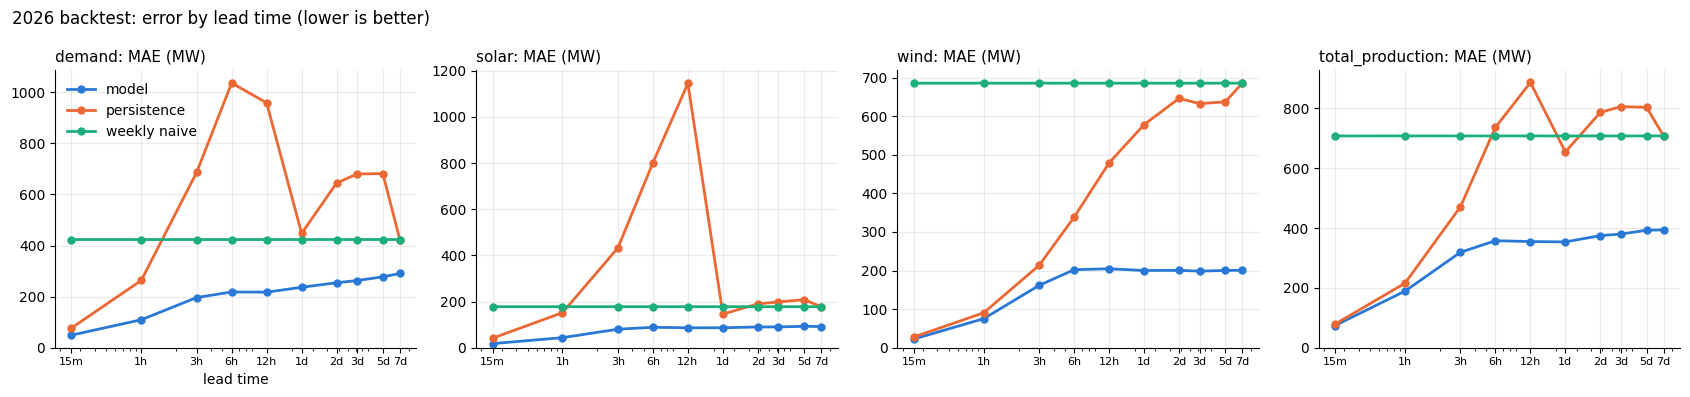

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharex=True)
for ax, name in zip(axes, ["demand", "solar", "wind", "total_production"]):
    r = results[results.series == name]
    ax.plot(r.lead_h, r.mae, color=C_MODEL, lw=2, marker="o", ms=5, label="model")
    ax.plot(r.lead_h, r.mae_persistence, color=C_PERSIST, lw=2, marker="o", ms=5, label="persistence")
    ax.plot(r.lead_h, r.mae_weekly_naive, color=C_WEEKLY, lw=2, marker="o", ms=5, label="weekly naive")
    ax.set_xscale("log")
    ax.set_xticks(LEADS_H, ["15m", "1h", "3h", "6h", "12h", "1d", "2d", "3d", "5d", "7d"], fontsize=8)
    ax.set_title(f"{name}: MAE (MW)", loc="left", fontsize=11)
    ax.set_ylim(bottom=0)
axes[0].legend(frameon=False)
axes[0].set_xlabel("lead time")
fig.suptitle("2026 backtest: error by lead time (lower is better)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(REPORT_DIR / "mae_by_lead.png", dpi=110)
plt.show()

### Example weeks
Full 7-day forecasts issued on a Monday 00:00 UTC, against what actually happened.

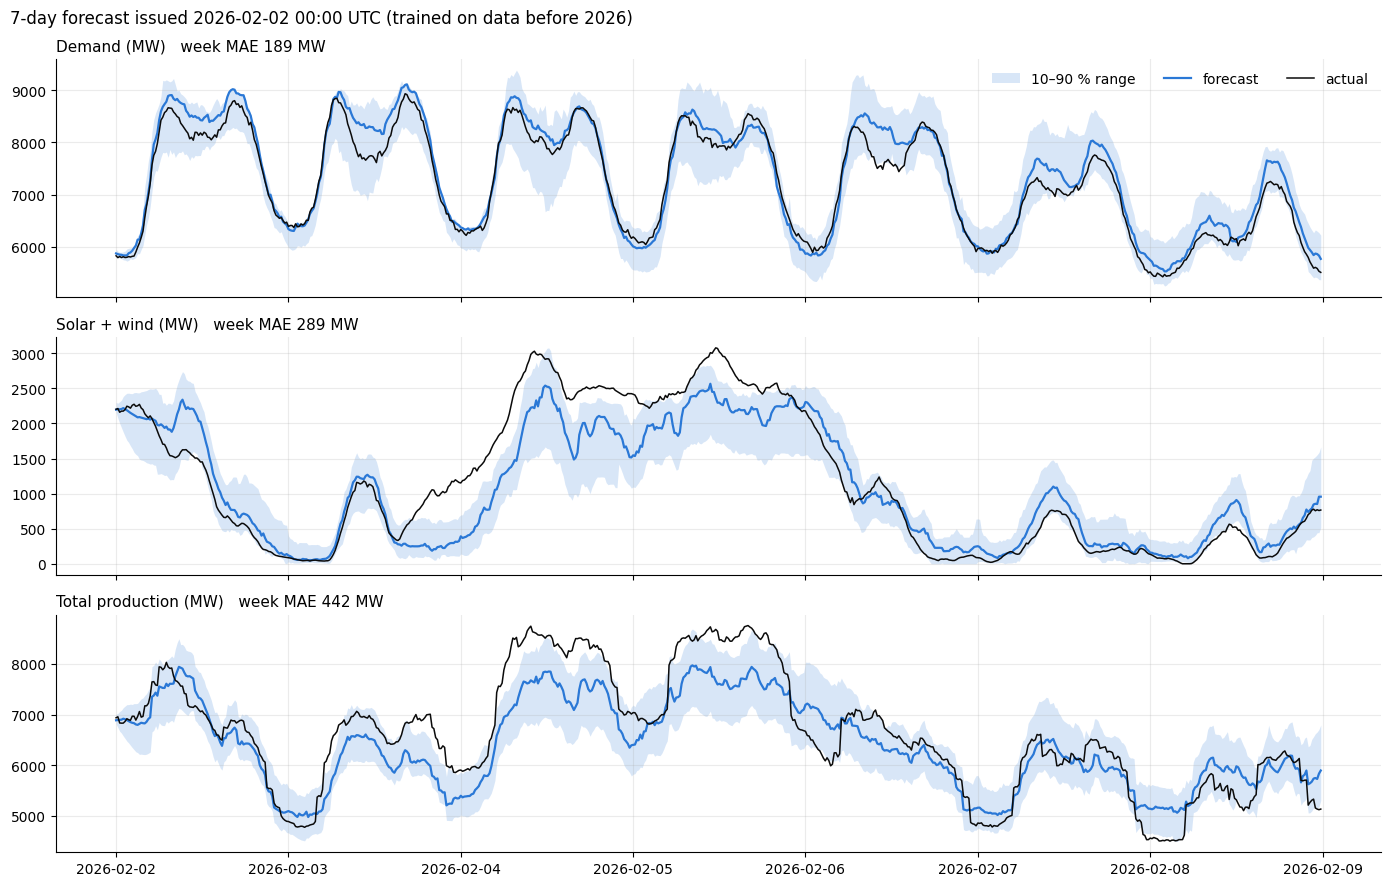

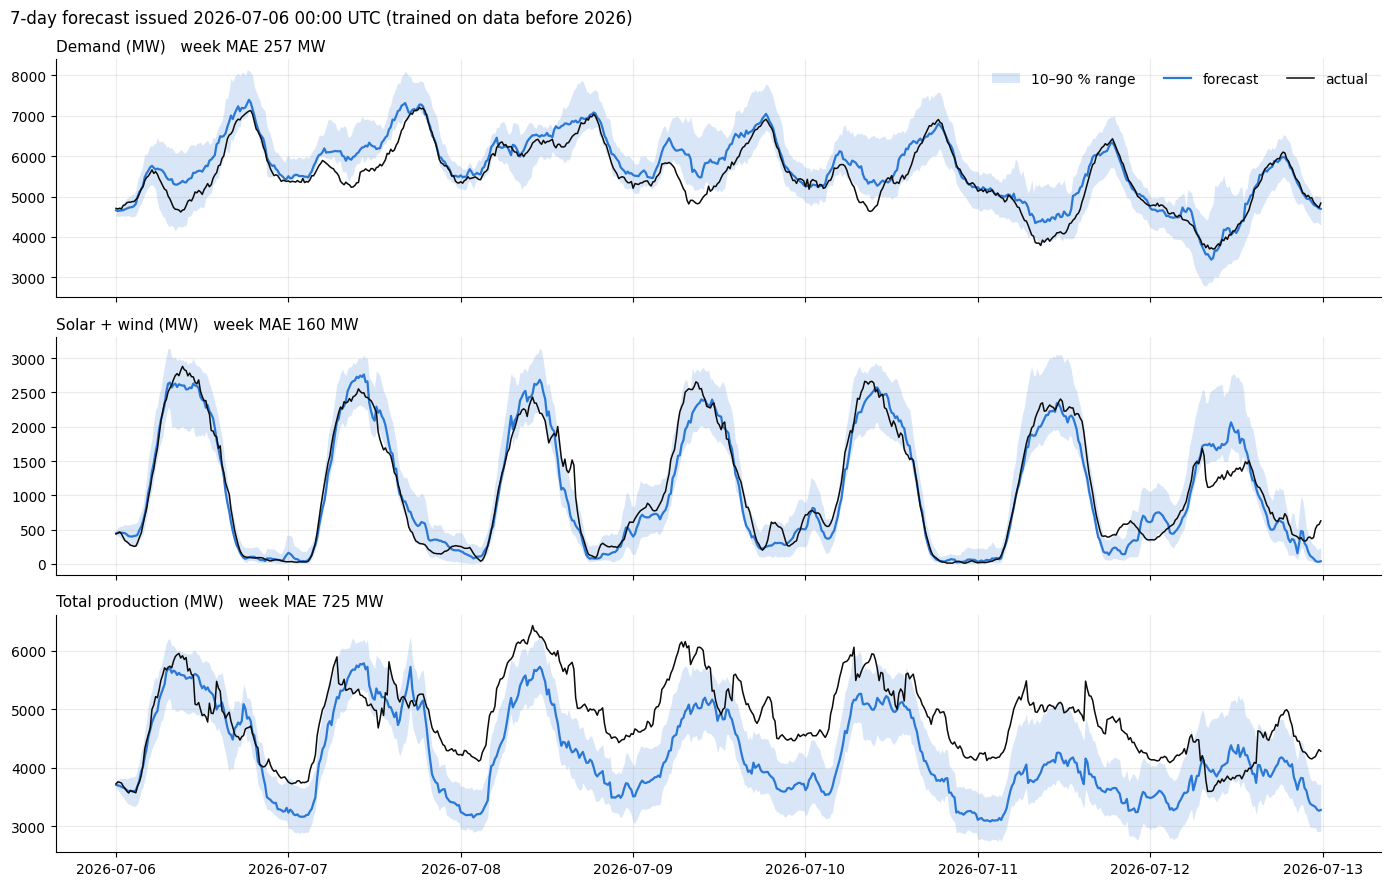

In [7]:
def plot_week(monday):
    issued = int(pd.Timestamp(monday, tz="UTC").timestamp())
    T = issued + np.arange(MAX_LEAD_STEPS) * STEP
    fc = forecast_all(T, issued)
    x = pd.to_datetime(T, unit="s")
    fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
    for ax, name, title in zip(axes, ["demand", "renewables", "total_production"],
                               ["Demand", "Solar + wind", "Total production"]):
        y = history(name).value(T)
        p = fc[name]
        ax.fill_between(x, p[:, 0], p[:, 2], color=C_MODEL, alpha=0.18, lw=0, label="10–90 % range")
        ax.plot(x, p[:, 1], color=C_MODEL, lw=1.6, label="forecast")
        ax.plot(x, y, color=C_ACTUAL, lw=1.1, label="actual")
        ax.set_title(f"{title} (MW)   week MAE {np.nanmean(np.abs(p[:, 1] - y)):.0f} MW", loc="left", fontsize=11)
    axes[0].legend(frameon=False, ncol=3, loc="upper right")
    fig.suptitle(f"7-day forecast issued {monday} 00:00 UTC (trained on data before 2026)", x=0.01, ha="left")
    fig.tight_layout()
    fig.savefig(REPORT_DIR / f"week_{monday}.png", dpi=110)
    plt.show()


for monday in ["2026-02-02", "2026-07-06"]:
    plot_week(monday)

### What the models use
Share of total split gain in each median model (%).

In [8]:
imp = pd.DataFrame({t: pd.Series(m["boosters"][0.5].feature_importance("gain"), index=m["features"])
                    for t, m in {**demand.models, **production.models}.items()})
(100 * imp / imp.sum()).round(1).sort_values("actual_total_load", ascending=False)

,actual_total_load,solar,wind_onshore,other_production
doy_sin,13.6,3.0,2.8,9.4
doy_cos,11.4,12.2,3.7,7.5
lead_hours,11.1,5.3,6.6,8.2
temperature_2m,8.1,5.7,2.3,2.8
quarter_of_day,6.8,9.8,0.7,7.6
base,5.2,8.6,5.5,7.3
weekday,5.0,0.6,1.1,4.7
mean_1d,5.0,2.8,26.7,8.7
shortwave_radiation,4.5,8.2,2.3,5.5
lag_week,4.3,2.3,1.0,17.1


## 3b. Understanding the results
Every plot below uses the models trained **before 2026**, scored on 2026 data they never saw.
Each series keeps the same colour in every plot. All plots are also saved to `reports/`.

In [9]:
from matplotlib.colors import LinearSegmentedColormap

LOCAL_TZ = "Europe/Bucharest"
SERIES_COLORS = {"demand": "#2a78d6", "solar": "#eda100", "wind": "#1baf7a",
                 "renewables": "#6250d6", "total_production": "#e87ba4"}
SERIES_LABEL = {"demand": "demand", "solar": "solar", "wind": "wind",
                "renewables": "solar + wind", "total_production": "total production"}
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
LEAD_LABELS = ["15m", "1h", "3h", "6h", "12h", "1d", "2d", "3d", "5d", "7d"]
INK, INK_2 = "#0b0b0b", "#52514e"


def lead_axis(ax):
    ax.set_xscale("log")
    ax.set_xticks(LEADS_H, LEAD_LABELS)
    ax.minorticks_off()
    ax.set_xlabel("lead time (how far ahead the forecast is)")


def save(fig, name):
    fig.tight_layout()
    fig.savefig(REPORT_DIR / name, dpi=110, bbox_inches="tight")
    plt.show()

### How much better than the simple rules?
Each cell is the **skill**: how much lower the model's error is than the better of the two
simple rules (repeat the last value, or copy the same time last week). 0 % means no better;
50 % means half the error.

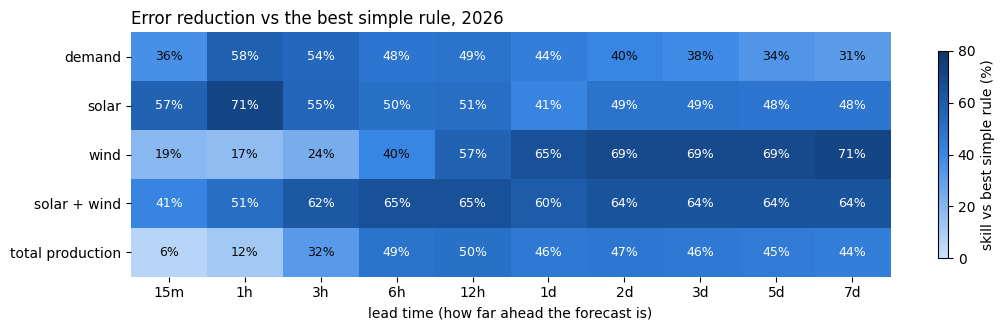

In [10]:
skill = pivot("skill_pct")
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(skill.values, cmap=LinearSegmentedColormap.from_list("blues", BLUES),
               vmin=0, vmax=80, aspect="auto")
ax.set_xticks(range(len(LEADS_H)), LEAD_LABELS)
ax.set_yticks(range(len(skill)), [SERIES_LABEL[s] for s in skill.index])
for i in range(skill.shape[0]):
    for j in range(skill.shape[1]):
        v = skill.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=9,
                color="white" if v > 40 else INK)
ax.grid(False)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
ax.set_xlabel("lead time (how far ahead the forecast is)")
fig.colorbar(im, ax=ax, label="skill vs best simple rule (%)", shrink=0.85)
ax.set_title("Error reduction vs the best simple rule, 2026", loc="left")
save(fig, "skill_heatmap.png")

**What it shows:** the model beats both simple rules everywhere. It is weakest for total production
and wind in the first hour: these change slowly, so "repeat the last value" is already very good.
It is strongest for wind from 1 day on (about 70 %), because the weather forecast sees wind changes
that no simple rule can, and for solar at 1 h (71 %), where the sun angle and cloud forecast predict
the morning ramp-up.

### How big is the error, in % of the typical value?
nMAE = average absolute error ÷ average actual value. This puts series of very different sizes
on one scale.

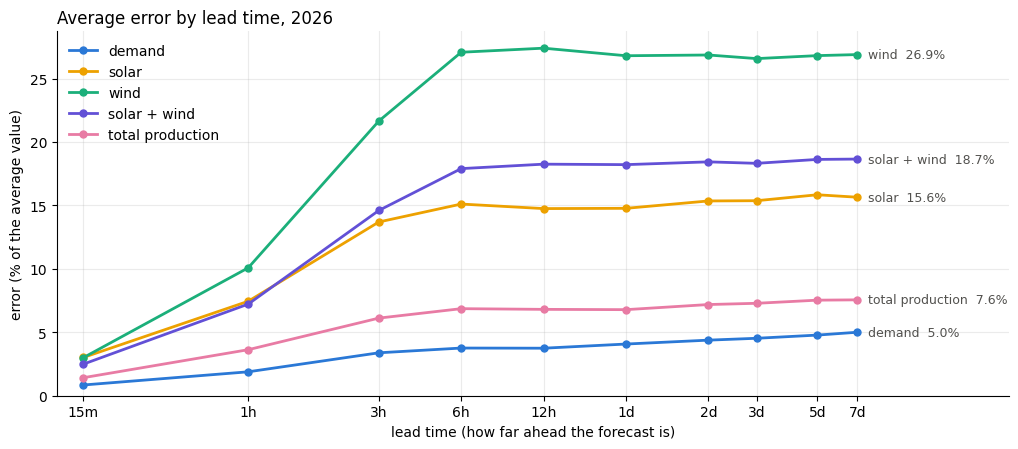

In [11]:
fig, ax = plt.subplots(figsize=(10.5, 4.6))
for name in SERIES_COL:
    r = results[results.series == name]
    ax.plot(r.lead_h, r.nmae_pct, color=SERIES_COLORS[name], lw=2, marker="o", ms=5,
            label=SERIES_LABEL[name])
    ax.annotate(f"{SERIES_LABEL[name]}  {r.nmae_pct.iloc[-1]:.1f}%", (r.lead_h.iloc[-1], r.nmae_pct.iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=INK_2)
lead_axis(ax)
ax.set_xlim(0.2, 600)
ax.set_ylim(bottom=0)
ax.set_ylabel("error (% of the average value)")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Average error by lead time, 2026", loc="left")
save(fig, "error_pct_by_lead.png")

**What it shows:** the error grows quickly over the first 6 hours, then stays almost flat. Up to
about 6 h the model leans on the latest values; beyond that it relies on the calendar and the
weather, which are about as good 1 day ahead as 7. Demand stays within 5 % and total production
within 8 % even at 7 days. Solar (16 %) and wind (27 %) are harder because they swing with the
weather. Caveat: the backtest used archived weather forecasts issued shortly before each time, so
real 5–7-day errors will be somewhat higher.

### Can the ranges be trusted?
Coverage = how often the actual value fell inside the 10–90 % range. The target is 80 %
(dashed line). Above 80 % means the range is wider than needed; below means too narrow.

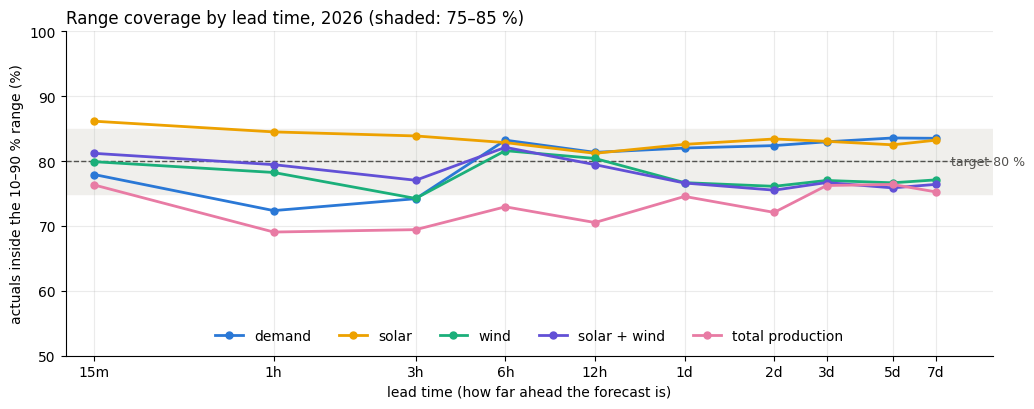

In [12]:
fig, ax = plt.subplots(figsize=(10.5, 4.2))
ax.axhspan(75, 85, color="#f0efec", zorder=0)
ax.axhline(80, color=INK_2, lw=1, ls="--")
ax.text(LEADS_H[-1] * 1.12, 80, "target 80 %", color=INK_2, fontsize=9, va="center")
for name in SERIES_COL:
    r = results[results.series == name]
    ax.plot(r.lead_h, r.coverage_80_pct, color=SERIES_COLORS[name], lw=2, marker="o", ms=5,
            label=SERIES_LABEL[name])
lead_axis(ax)
ax.set_ylim(50, 100)
ax.set_xlim(0.2, 260)
ax.set_ylabel("actuals inside the 10–90 % range (%)")
ax.legend(frameon=False, ncol=5, loc="lower center")
ax.set_title("Range coverage by lead time, 2026 (shaded: 75–85 %)", loc="left")
save(fig, "range_coverage.png")

**What it shows:** most series stay in the 75–85 % band, so their ranges are honest. The exception is
total production (69–77 %): its range is somewhat too narrow, especially between 1 h and 12 h, so
read it as roughly a 70 % range. Solar is slightly too wide at short leads (84–86 %), which is safe.

The next plots zoom in on **day-ahead forecasts** (issued 24 h before each interval), the
lead time used to plan the battery against the 96 day-ahead prices.

In [13]:
DETAIL_LEAD_H = 24
issued_24 = T_test - int((DETAIL_LEAD_H - 0.25) * 3600)
fc_24 = forecast_all(T_test, issued_24)
local = pd.to_datetime(T_test, unit="s", utc=True).tz_convert(LOCAL_TZ)
detail = {}
for name in SERIES_COL:
    y = history(name).value(T_test)
    weekly = history(name).value(T_test - WEEK)          # the simple rule at this lead
    detail[name] = pd.DataFrame({"y": y, "pred": fc_24[name][:, 1], "low": fc_24[name][:, 0],
                                 "high": fc_24[name][:, 2], "weekly": weekly,
                                 "hour": local.hour, "month": local.month}).dropna()

### When in the day is the forecast wrong?
Average error by hour of the day (Romanian local time), for the model and for the simple rule
"same time last week".

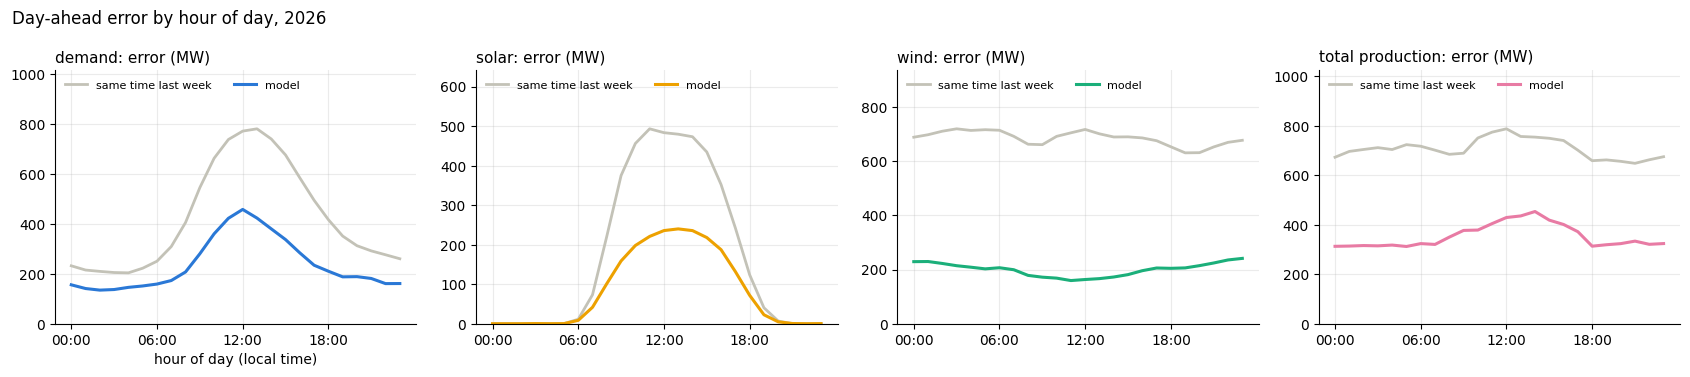

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, name in zip(axes, ["demand", "solar", "wind", "total_production"]):
    d = detail[name]
    by_hour = d.assign(err=(d.pred - d.y).abs(), err_w=(d.weekly - d.y).abs()).groupby("hour")[["err", "err_w"]].mean()
    ax.plot(by_hour.index, by_hour.err_w, color="#c3c2b7", lw=2, label="same time last week")
    ax.plot(by_hour.index, by_hour.err, color=SERIES_COLORS[name], lw=2.2, label="model")
    ax.set_xticks(range(0, 24, 6), [f"{h:02d}:00" for h in range(0, 24, 6)])
    ax.set_ylim(0, 1.3 * by_hour.max().max())
    ax.set_title(f"{SERIES_LABEL[name]}: error (MW)", loc="left", fontsize=11)
    ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=2)
axes[0].set_xlabel("hour of day (local time)")
fig.suptitle("Day-ahead error by hour of day, 2026", x=0.01, ha="left")
save(fig, "error_by_hour.png")

**What it shows:** demand is hardest to forecast around midday (12:00–13:00). Rooftop solar that the
grid can't see lowers measured demand by an amount that depends on the clouds. Solar errors follow
the sun and are zero at night. Wind errors are about the same at every hour. Total production peaks
at midday like demand. In every panel the model's error is roughly half of "same time last week",
or less.

### Which months are hard?
Average day-ahead error per month of 2026, next to the average actual value for scale.

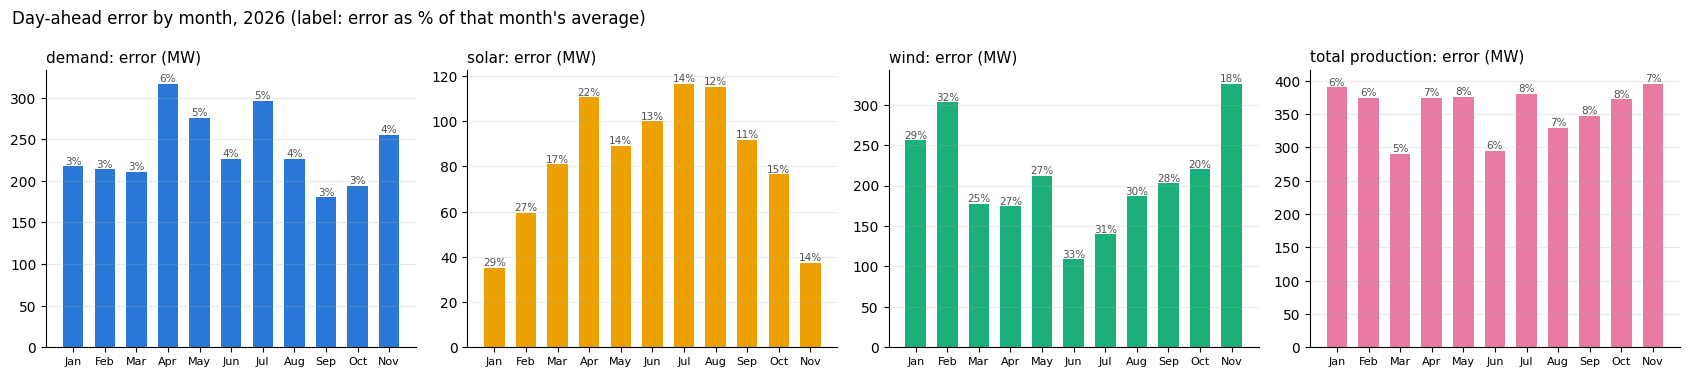

In [15]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, name in zip(axes, ["demand", "solar", "wind", "total_production"]):
    d = detail[name]
    g = d.assign(err=(d.pred - d.y).abs()).groupby("month").agg(err=("err", "mean"), y=("y", "mean"))
    ax.bar(g.index, g.err, color=SERIES_COLORS[name], width=0.65)
    for m, row in g.iterrows():
        ax.text(m, row.err, f"{100 * row.err / row.y:.0f}%", ha="center", va="bottom", fontsize=7.5, color=INK_2)
    ax.set_xticks(g.index, [MONTHS[m - 1] for m in g.index], fontsize=8)
    ax.set_title(f"{SERIES_LABEL[name]}: error (MW)", loc="left", fontsize=11)
    ax.grid(axis="x", visible=False)
fig.suptitle("Day-ahead error by month, 2026 (label: error as % of that month's average)", x=0.01, ha="left")
save(fig, "error_by_month.png")

**What it shows:** demand is hardest in April, May and July (spring and summer, when solar and air
conditioning vary most). Solar has its largest errors in MW in summer, yet its lowest relative
errors (12–14 %); winter's 29 % is a large share of a small number. Wind is worst in February and
November, the stormy months. Total production stays at 5–8 % in every month.

### Forecast vs actual
Each dot (shaded by how many fall there) is one 15-min interval of 2026. A perfect forecast
sits on the diagonal; above it the model over-forecasts, below it under-forecasts.

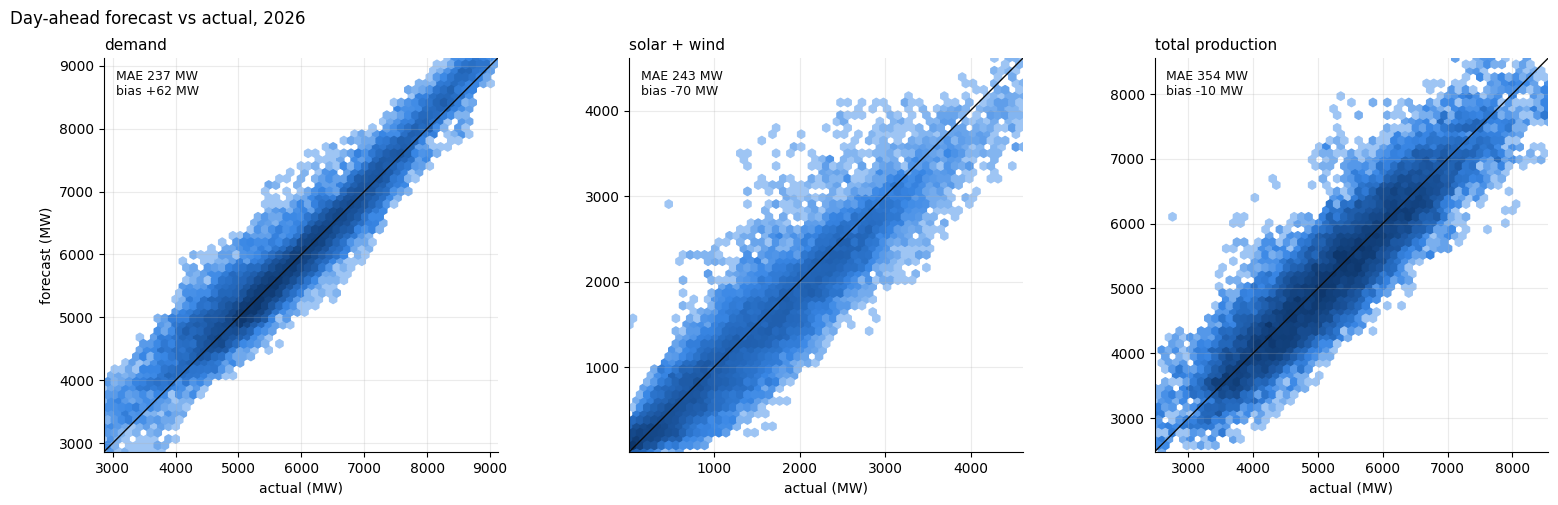

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, name in zip(axes, ["demand", "renewables", "total_production"]):
    d = detail[name]
    lo, hi = np.percentile(np.r_[d.y, d.pred], [0.2, 99.8])
    ax.hexbin(d.y, d.pred, gridsize=55, extent=(lo, hi, lo, hi), mincnt=1, bins="log",
              cmap=LinearSegmentedColormap.from_list("b", BLUES[1:]))
    ax.plot([lo, hi], [lo, hi], color=INK, lw=1)
    mae, bias = np.mean(np.abs(d.pred - d.y)), np.mean(d.pred - d.y)
    ax.text(0.03, 0.97, f"MAE {mae:.0f} MW\nbias {bias:+.0f} MW", transform=ax.transAxes,
            va="top", fontsize=9, color=INK)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal")
    ax.set_xlabel("actual (MW)")
    ax.set_title(SERIES_LABEL[name], loc="left", fontsize=11)
axes[0].set_ylabel("forecast (MW)")
fig.suptitle("Day-ahead forecast vs actual, 2026", x=0.01, ha="left")
save(fig, "forecast_vs_actual.png")

**What it shows:** demand sits tightly around the diagonal, with a small over-forecast (+62 MW on
average), because 2026 demand is lower than in the training years. Solar + wind spread more widely
and are under-forecast on the highest days (−70 MW): very windy days are underestimated. Total
production has no overall bias but a wide spread, from the dispatched part of the mix
(nuclear, gas, hydro).

### How the forecast sharpens as the day approaches
The same day (Wednesday 8 July 2026), forecast 6 days, 3 days, 1 day and 1 hour before it
starts. Darker lines are issued closer to the day; black is what happened.

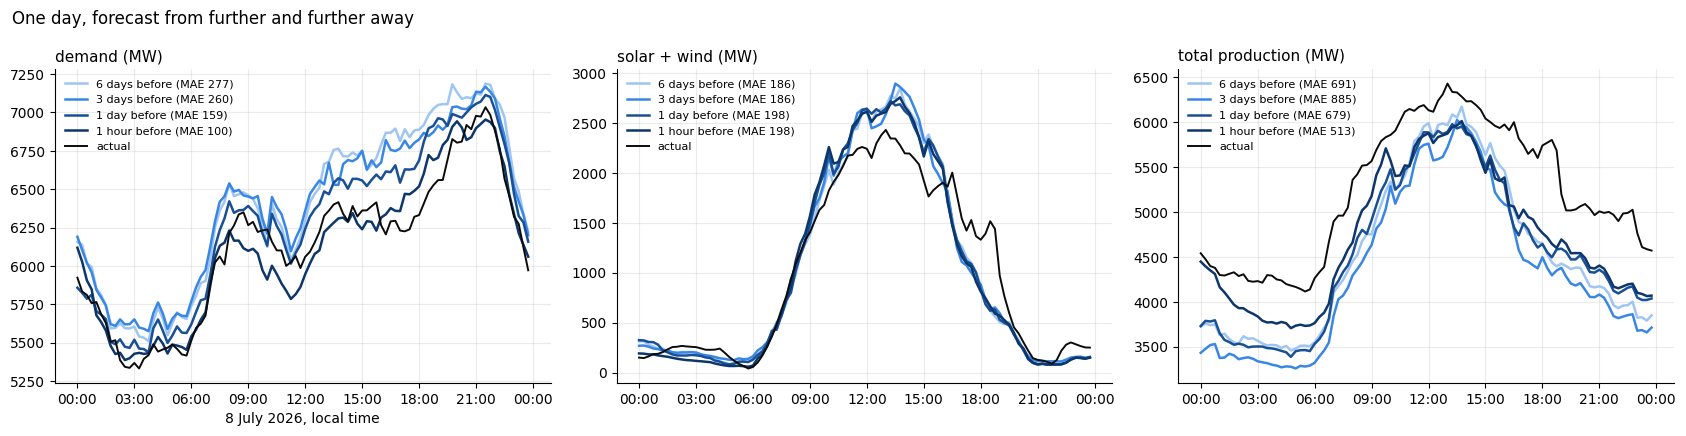

In [17]:
day = pd.Timestamp("2026-07-08", tz=LOCAL_TZ)
day_start = int(day.tz_convert("UTC").timestamp())
T_day = day_start + np.arange(96) * STEP
x = pd.to_datetime(T_day, unit="s", utc=True).tz_convert(LOCAL_TZ).tz_localize(None)
before = [(6 * DAY, "6 days before", BLUES[1]), (3 * DAY, "3 days before", BLUES[3]),
          (DAY, "1 day before", BLUES[5]), (3600, "1 hour before", BLUES[6])]
runs = [(label, color, forecast_all(T_day, day_start - lead)) for lead, label, color in before]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), sharex=True)
for ax, name in zip(axes, ["demand", "renewables", "total_production"]):
    y = history(name).value(T_day)
    for label, color, fc in runs:
        mae = np.nanmean(np.abs(fc[name][:, 1] - y))
        ax.plot(x, fc[name][:, 1], color=color, lw=1.8, label=f"{label} (MAE {mae:.0f})")
    ax.plot(x, y, color=INK, lw=1.4, label="actual")
    ax.set_title(f"{SERIES_LABEL[name]} (MW)", loc="left", fontsize=11)
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
    ax.legend(frameon=False, fontsize=8)
axes[0].set_xlabel("8 July 2026, local time")
fig.suptitle("One day, forecast from further and further away", x=0.01, ha="left")
save(fig, "forecast_sharpening.png")

**What it shows:** the demand forecast improves steadily as the day approaches, from an error of
277 MW six days ahead to 100 MW one hour ahead, because the latest values start to matter. Solar +
wind barely change with lead time: they depend on the weather forecast, and the backtest weather is
the same for every lead. Total production misses the evening (18:00–24:00) by up to about 800 MW at
every lead. That part of the mix follows exports and the market, which the model has no data on;
day-ahead prices would help most here.

## 4. Final models: train on all data and save
Same recipe, cut-off = end of the data (the last 3 months are used for early stopping and
calibration, then included in the refit). These are the models the app and API load.

In [18]:
t0 = time.time()
for cls in (DemandForecaster, ProductionForecaster):
    print(f"saved -> {cls.fit(data).save()}")
print(f"total {time.time() - t0:.0f} s")

[demand_model] actual_total_load    559,000 samples   trees/quantile [581, 1399, 477]      67 s


saved -> C:\Users\teodo\Desktop\smarthack2026\GitRekt\predictions\models\demand_model.pkl


[production_model] solar                556,317 samples   trees/quantile [593, 1603, 1150]      89 s


[production_model] wind_onshore         548,614 samples   trees/quantile [846, 454, 123]      45 s


[production_model] other_production     559,000 samples   trees/quantile [56, 856, 205]      35 s


saved -> C:\Users\teodo\Desktop\smarthack2026\GitRekt\predictions\models\production_model.pkl
total 238 s


## 5. Use the saved models
`predict()` takes any timestamps (unsorted, irregular, snapped to 15 min) from `issued_at` up to
7 days later. Weather per timestamp: archive in `dataset.csv` → live Open-Meteo forecast
(≤ 16 days) → climatology.

In [19]:
demand_model = DemandForecaster.load()
production_model = ProductionForecaster.load()
now = demand_model.last_known_ts + STEP
ts = [now, now + 900, now + 3 * 3600, now + DAY + 1234, now + 3 * DAY, now + 7 * DAY - STEP]
display(demand_model.predict(ts))
production_model.predict(ts)

,timestamp,time_utc,lead_hours,demand_mw,demand_low_mw,demand_high_mw,weather_source
0,1794050100,2026-11-07 11:15:00,0.2,4764.9,4555.8,4808.5,archive
1,1794051000,2026-11-07 11:30:00,0.5,4858.7,4642.3,4957.6,forecast
2,1794060900,2026-11-07 14:15:00,3.2,6070.2,5745.8,6599.8,forecast
3,1794137400,2026-11-08 11:30:00,24.5,5000.5,4165.3,5665.6,forecast
4,1794309300,2026-11-10 11:15:00,72.2,7223.7,6603.7,7760.1,forecast
5,1794654000,2026-11-14 11:00:00,168.0,6454.5,4973.2,7563.4,forecast


,timestamp,time_utc,lead_hours,solar_mw,solar_low_mw,solar_high_mw,wind_mw,wind_low_mw,wind_high_mw,prod_low_mw,prod_high_mw,total_mw,total_low_mw,total_high_mw,weather_source
0,1794050100,2026-11-07 11:15:00,0.2,1906.6,1825.1,1980.3,2588.4,2527.3,2700.9,4395.6,4621.7,7142.6,6984.6,7313.5,archive
1,1794051000,2026-11-07 11:30:00,0.5,1848.5,1765.2,1997.1,2534.8,2447.3,2654.0,4267.4,4568.5,7044.4,6877.1,7312.3,forecast
2,1794060900,2026-11-07 14:15:00,3.2,301.1,76.4,469.5,2108.6,1668.8,2479.7,1934.4,2799.6,6025.5,5199.1,6729.9,forecast
3,1794137400,2026-11-08 11:30:00,24.5,1923.9,1676.7,2058.2,108.9,0.0,914.1,1686.8,2829.5,4747.6,3971.1,5543.5,forecast
4,1794309300,2026-11-10 11:15:00,72.2,1185.1,847.7,1467.7,84.4,47.5,1182.7,826.5,2393.2,4682.9,3972.5,5845.5,forecast
5,1794654000,2026-11-14 11:00:00,168.0,281.3,210.7,632.7,1548.7,1468.7,2547.3,1709.5,2898.8,5185.1,4005.1,6312.9,forecast
